In [35]:

import os
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [36]:
train = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
sample = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv')

In [37]:
print(train.shape)
print(test.shape)

(2000, 8)
(500, 7)


In [38]:
train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [39]:
train.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [40]:
print("Duplicate Rows:", train_df.duplicated().sum())

Duplicate Rows: 0


In [41]:
train["answer"].value_counts()

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

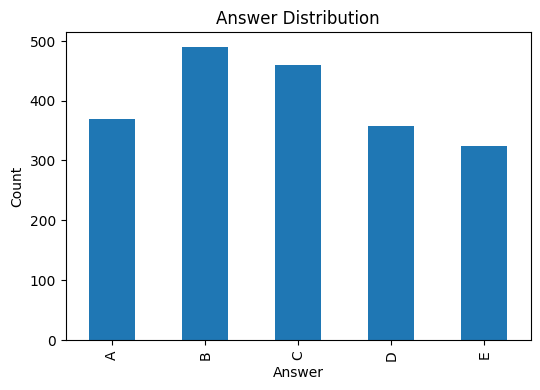

In [42]:
import matplotlib.pyplot as plt

train["answer"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6,4)
)

plt.title("Answer Distribution")
plt.xlabel("Answer")
plt.ylabel("Count")
plt.show()

In [43]:
train["prompt_length"] = train_df["prompt"].str.len()

train["prompt_length"].describe()

count    2000.000000
mean      117.669500
std        44.408674
min        19.000000
25%        87.750000
50%       111.000000
75%       141.000000
max       337.000000
Name: prompt_length, dtype: float64

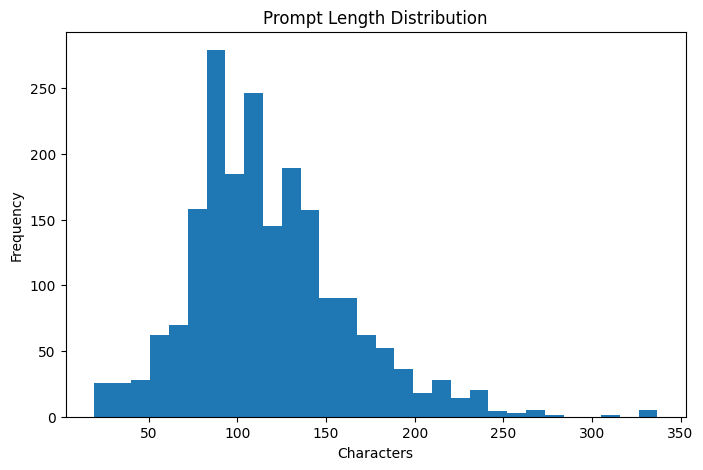

In [44]:
plt.figure(figsize=(8,5))

plt.hist(train_df["prompt_length"], bins=30)

plt.title("Prompt Length Distribution")

plt.xlabel("Characters")

plt.ylabel("Frequency")

plt.show()

In [45]:
for col in ["A","B","C","D","E"]:
    train[f"{col}_len"] = train_df[col].str.len()

In [46]:
train[["A_len","B_len","C_len","D_len","E_len"]].mean()

A_len    164.0915
B_len    166.6165
C_len    167.2270
D_len    162.5635
E_len    164.2300
dtype: float64

In [47]:
def build_text(row):
    return (
        f"Question: {row['prompt']}\n\n"
        f"A. {row['A']}\n"
        f"B. {row['B']}\n"
        f"C. {row['C']}\n"
        f"D. {row['D']}\n"
        f"E. {row['E']}"
    )

train["text"] = train.apply(build_text, axis=1)
test["text"] = test.apply(build_text, axis=1)

In [48]:
print(train["text"].iloc[0])

Question: Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.

A. Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the past involves acknowledging it as a historical era, and the relationship to the future involves creating a world that will endure beyond one's own time.
B. Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement.
C. Martin Heidegger does not believe in the existence of time or that it has any effect on human consciousness. The relationship to the past and the future is insignificant, and human existence is solely based on the present.
D. Martin Heidegger believes that the relations